# Information encoding-decoding evaluation metrics

This notebook converts the summary table from `Evaluation_metrics_exptoseed.ipynb` and `Evaluation_metrics_simtoseed.ipynb` into a publication-ready three-panel bar figure:

1. MSE loss
2. Dice loss, with its y-axis on the left
3. Tolerance precision, recall, and F1 score grouped by metric

Bars show the mean and error bars show one standard deviation. Error bars for bounded metrics are clipped to the valid interval [0, 1]. Pixel accuracy is intentionally omitted because the requested figure focuses on MSE, Dice loss, and tolerance metrics.

The diffusion-trained comparison is evaluated with the same **last.ckpt** as Figure 5E, on the full 132-image test cohort. Checkpoint identity and inference settings are saved in `source_data/inverse_metrics_fig5/evaluation_provenance.json`.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%config InlineBackend.figure_format = 'retina'

from utils.evaluation_results import load_seed_metric_summary

# Values are saved by the two evaluation notebooks, never typed into this plot.
results = load_seed_metric_summary()

results.round(3)

,comparison,n_images,mse_mean,mse_std,dice_mean,dice_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,Diffusion model\nExperiment→Seed,132,0.016,0.012,0.950,0.106,0.785,0.200,0.677,0.282,0.683,0.217
1,Simulation model\nExperiment→Seed,132,0.013,0.009,0.995,0.029,0.377,0.365,0.190,0.235,0.218,0.224
2,Simulation model\nSimulation→Seed,107,0.001,0.003,0.022,0.054,0.994,0.022,0.977,0.060,0.984,0.037


In [3]:
# Keep colors consistent by model and conditioning source.
comparison_colors = ['#1AA3D6', '#FF7F0E', '#FDBA74']

import matplotlib.font_manager as fm

PLOT_FONT_PATH = Path('/hpc/group/youlab/ks723/miniconda3/Lingchong/fonts/ARIAL.TTF')
if not PLOT_FONT_PATH.is_file():
    raise FileNotFoundError(f'Arial font file not found: {PLOT_FONT_PATH}')
fm.fontManager.addfont(str(PLOT_FONT_PATH))
PLOT_FONT_FAMILY = fm.FontProperties(fname=str(PLOT_FONT_PATH)).get_name()
PLOT_FONT_SIZE = 38
PLOT_TITLE_FONTSIZE = 38
PLOT_TICK_FONTSIZE = 38
PLOT_LEGEND_FONTSIZE = 38

plt.rcParams.update(
    {
        'font.family': PLOT_FONT_FAMILY,
        'font.size': PLOT_FONT_SIZE,
        'axes.spines.top': False,
        'axes.titleweight': 'bold',
        'figure.dpi': 130,
        'savefig.dpi': 600,
    }
)


def bounded_yerr(means, stds, lower=0.0, upper=None):
    """Return asymmetric errors clipped to the metric's valid range."""
    means = np.asarray(means, dtype=float)
    stds = np.asarray(stds, dtype=float)
    lower_error = np.minimum(stds, means - lower)
    upper_error = stds if upper is None else np.minimum(stds, upper - means)
    return np.vstack([lower_error, upper_error])


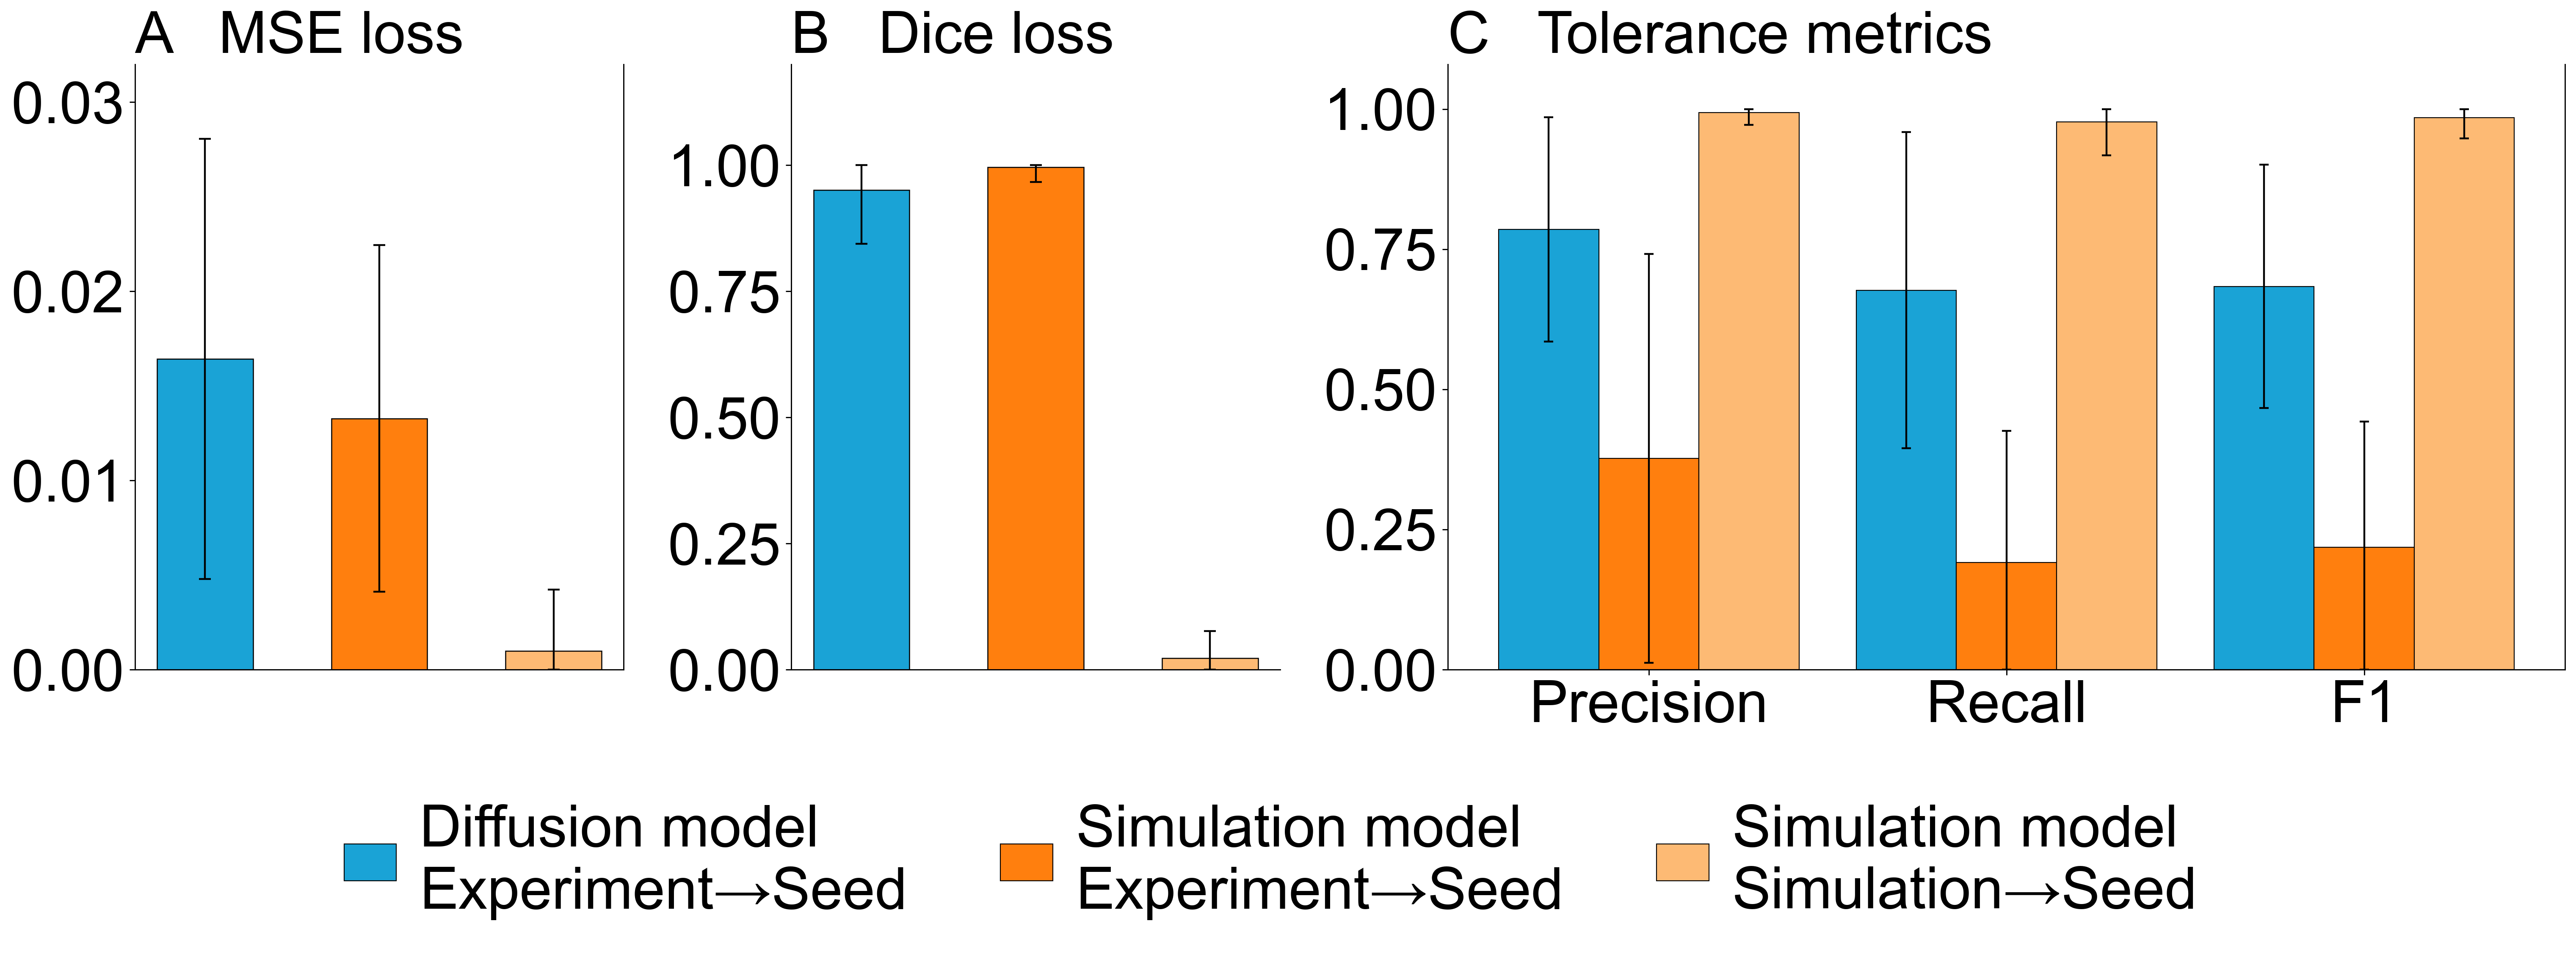

In [4]:
labels = results['comparison'].to_numpy()
x = np.arange(len(results))
error_kw = {'elinewidth': 1.2, 'capthick': 1.2}

fig, axes = plt.subplots(1, 3, figsize=(24, 10), gridspec_kw={'width_ratios': [0.7, 0.7, 1.6]})
ax_mse, ax_dice, ax_tolerance = axes

# Panel A: MSE loss
mse_bars = ax_mse.bar(
    x,
    results['mse_mean'],
    yerr=bounded_yerr(results['mse_mean'], results['mse_std']),
    width=0.55,
    color=comparison_colors,
    edgecolor='black',
    linewidth=0.7,
    capsize=4,
    error_kw=error_kw,
)
ax_mse.set_title('A   MSE loss', loc='left', fontsize=PLOT_TITLE_FONTSIZE, fontfamily=PLOT_FONT_FAMILY)
ax_mse.set_xticks(x, labels)
ax_mse.tick_params(axis='x', bottom=False, labelbottom=False)
ax_mse.set_ylim(0, 0.032)

# Panel B: Dice loss, with ticks on the left.
dice_bars = ax_dice.bar(
    x,
    results['dice_mean'],
    yerr=bounded_yerr(results['dice_mean'], results['dice_std'], upper=1.0),
    width=0.55,
    color=comparison_colors,
    edgecolor='black',
    linewidth=0.7,
    capsize=4,
    error_kw=error_kw,
)
ax_dice.set_title('B   Dice loss', loc='left', fontsize=PLOT_TITLE_FONTSIZE, fontfamily=PLOT_FONT_FAMILY)
ax_dice.yaxis.tick_left()
ax_dice.spines['right'].set_visible(False)
ax_dice.spines['left'].set_visible(True)
ax_dice.set_xticks(x, labels)
ax_dice.tick_params(axis='x', bottom=False, labelbottom=False)
ax_dice.set_ylim(0, 1.2)

# Panel C: group comparisons within each tolerance metric.
metric_specs = [
    ('Precision', 'precision_mean', 'precision_std'),
    ('Recall', 'recall_mean', 'recall_std'),
    ('F1', 'f1_mean', 'f1_std'),
]
width = 0.28
metric_positions = np.arange(len(metric_specs))
offsets = (np.arange(len(results)) - (len(results) - 1) / 2) * width
for comparison_index, row in results.reset_index(drop=True).iterrows():
    means = np.array([row[mean_col] for _, mean_col, _ in metric_specs], dtype=float)
    stds = np.array([row[std_col] for _, _, std_col in metric_specs], dtype=float)
    ax_tolerance.bar(
        metric_positions + offsets[comparison_index],
        means,
        width=width,
        yerr=bounded_yerr(means, stds, upper=1.0),
        label=labels[comparison_index],
        color=comparison_colors[comparison_index],
        edgecolor='black',
        linewidth=0.6,
        capsize=3,
        error_kw=error_kw,
    )

ax_tolerance.set_title('C   Tolerance metrics', loc='left', fontsize=PLOT_TITLE_FONTSIZE, fontfamily=PLOT_FONT_FAMILY)
ax_tolerance.set_xticks(metric_positions, [metric for metric, _, _ in metric_specs])
ax_tolerance.set_ylim(0, 1.08)
handles, legend_labels = ax_tolerance.get_legend_handles_labels()
fig.subplots_adjust(bottom=0.29, left=0.07, right=0.99, top=0.84, wspace=0.24)
fig.legend(
    handles,
    legend_labels,
    loc='lower center',
    ncol=len(legend_labels),
    bbox_to_anchor=(0.5, 0.015),
    frameon=False,
    prop={'family': PLOT_FONT_FAMILY, 'size': PLOT_LEGEND_FONTSIZE},
    handlelength=0.9,
    handleheight=0.6,
    handletextpad=0.4,
    columnspacing=1.6,
)

for ax in axes:
    ax.grid(False)
    ax.tick_params(axis='y', labelsize=PLOT_TICK_FONTSIZE)
    for tick_label in ax.get_yticklabels():
        tick_label.set_fontfamily(PLOT_FONT_FAMILY)

ax_tolerance.tick_params(axis='x', labelsize=PLOT_TICK_FONTSIZE)
for tick_label in ax_tolerance.get_xticklabels():
    tick_label.set_fontfamily(PLOT_FONT_FAMILY)

# fig.suptitle(
#     'Information encoding-decoding evaluation metrics',
#     fontsize=PLOT_TITLE_FONTSIZE,
#     fontweight='bold',
#     fontfamily=PLOT_FONT_FAMILY,
# )
plt.show()

In [5]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Fig. 5F — inverse-decoder evaluation metrics
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'information_encoding_decoding' / 'vector based plots'

save_vector_pdf(fig, VECTOR_DIR / 'Fig5F_inverse_metrics.pdf')
for _axis, _label in zip(axes, ('MSE', 'Dice', 'tolerance_metrics')):
    save_vector_pdf(fig, VECTOR_DIR / f'Fig5F_{_label}.pdf', panel=_axis)


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/information_encoding_decoding/vector based plots/Fig5F_inverse_metrics.pdf
Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/information_encoding_decoding/vector based plots/Fig5F_MSE.pdf


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/information_encoding_decoding/vector based plots/Fig5F_Dice.pdf


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/information_encoding_decoding/vector based plots/Fig5F_tolerance_metrics.pdf


In [6]:
# Save both an editable vector figure and a high-resolution raster figure.
output_dir = Path('figures')
output_dir.mkdir(exist_ok=True)

for extension in ('pdf', 'png'):
    fig.savefig(
        output_dir / f'information_encoding_decoding_evaluation_barplots.{extension}',
        bbox_inches='tight',
    )

print(f'Saved figures to: {output_dir.resolve()}')



Saved figures to: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/information_encoding_decoding/figures
